# 03 · CO2: Sentiment analysis & information extraction (8 marks)
**Sentiment**: VADER (rule/lexicon) vs TF-IDF + Naive Bayes vs TF-IDF + Logistic Regression on SST-2,
then applied to exam questions (tone, negation, hedging as difficulty signals).

**Information extraction**: named entities, keyphrases (YAKE, RAKE, TextRank), subject-verb-object triples,
numbers / units / formulas, Bloom's-taxonomy cognitive level, with evaluation on hand-labelled gold data.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
pd.set_option('display.max_colwidth', 120)
REPORTS = ROOT / 'reports'; FIG = REPORTS / 'figures'
def show(name): display(Image(filename=str(FIG / name)))
def rj(name): return json.loads((REPORTS / name).read_text())

## Sentiment analysis models

In [2]:
sm = rj('sentiment_metrics.json')
pd.DataFrame({k:v for k,v in sm.items() if isinstance(v,dict) and 'macro_f1' in v}).T.round(4)

,accuracy,macro_f1
VADER (rule-based),0.6250,0.6007
TF-IDF + Naive Bayes,0.8222,0.8210
TF-IDF + Logistic Regression,0.8200,0.8192


In [3]:
pd.DataFrame(sm['classification_report_lr']).T.round(3)

,precision,recall,f1-score,support
negative,0.848,0.771,0.808,428.00
positive,0.797,0.867,0.831,444.00
accuracy,0.820,0.820,0.820,0.82
macro avg,0.823,0.819,0.819,872.00
weighted avg,0.822,0.820,0.819,872.00


In [4]:
from src.nlp.sentiment import analyze
for t in ['This is a wonderful and easy question!', 'Unfortunately, which of the following is NOT a cause of the terrible famine?',
          'What is the boiling point of water?']:
    print(analyze(t), '|', t)

{'ml_positive_prob': 0.959, 'vader_compound': 0.784, 'vader_label': 'positive', 'vader_pos': 0.633, 'vader_neg': 0.0, 'vader_neu': 0.367} | This is a wonderful and easy question!
{'ml_positive_prob': 0.006, 'vader_compound': -0.6705, 'vader_label': 'negative', 'vader_pos': 0.0, 'vader_neg': 0.355, 'vader_neu': 0.645} | Unfortunately, which of the following is NOT a cause of the terrible famine?
{'ml_positive_prob': 0.277, 'vader_compound': 0.0, 'vader_label': 'neutral', 'vader_pos': 0.0, 'vader_neg': 0.0, 'vader_neu': 1.0} | What is the boiling point of water?


### Does question tone relate to difficulty?

In [5]:
pd.read_csv(REPORTS/'sentiment_vs_difficulty.csv').round(3)

,level,n,vader_mean,ml_pos_mean,pct_negative,pct_neutral
0,Easy,1542,0.088,0.455,0.121,0.574
1,Hard,1162,0.114,0.465,0.153,0.403
2,Medium,1481,0.116,0.491,0.106,0.544


In [6]:
import seaborn as sns
from src.config import DATA_PROC
f = pd.read_parquet(DATA_PROC/'features_train.parquet'); tr = pd.read_parquet(DATA_PROC/'train.parquet'); f['level']=tr.level.values
display(f.groupby('level')[['vader_compound','n_negations','n_constraints','n_hedges']].mean().round(3).loc[['Easy','Medium','Hard']])

,vader_compound,n_negations,n_constraints,n_hedges
level,,,,
Easy,0.073,0.042,0.073,0.096
Medium,0.113,0.146,0.153,0.191
Hard,0.122,0.198,0.356,0.109


Questions are mostly **neutral** in tone. Hard questions carry more constraint words ("exactly", "at least",
"distinct") and negations ("NOT", "EXCEPT"), which is why tone features are part of the difficulty model.

## Information extraction

In [7]:
from src.nlp.info_extraction import extract
for q in ['Calculate the force needed to accelerate a 1200 kg car from rest to 25 m/s in 8 seconds on the Mumbai-Pune expressway.',
          'Evaluate the impact of the Treaty of Versailles on the rise of fascism in Europe.',
          'Which of the following is NOT a function of the mitochondria?']:
    print('\nQ:', q); r = extract(q)
    for k in ['question_type','bloom_level','bloom_indicators','entities','keyphrases_yake','keyphrases_textrank','keyphrases_rake','svo_triples','numbers','quantities_with_units']:
        print(f'   {k:22s}', r[k])


Q: Calculate the force needed to accelerate a 1200 kg car from rest to 25 m/s in 8 seconds on the Mumbai-Pune expressway.


   question_type          imperative / statement completion
   bloom_level            Apply
   bloom_indicators       ['calculate (Apply)']
   entities               [{'text': '1200 kg', 'label': 'QUANTITY'}, {'text': '25', 'label': 'CARDINAL'}, {'text': '8 seconds', 'label': 'TIME'}, {'text': 'Mumbai', 'label': 'GPE'}]
   keyphrases_yake        ['Calculate the force', 'Mumbai-Pune expressway', 'force needed', 'needed to accelerate', 'car from rest']
   keyphrases_textrank    ['mumbai pune expressway', 'rest', '8 seconds', '1200 kg car', 'force']
   keyphrases_rake        ['1200 kg car', 'pune expressway', 'force needed', '8 seconds', 'rest']
   svo_triples            []
   numbers                ['1200', '25', '8']
   quantities_with_units  ['1200 kg', '25 m', '8 seconds']

Q: Evaluate the impact of the Treaty of Versailles on the rise of fascism in Europe.
   question_type          imperative / statement completion
   bloom_level            Evaluate
   bloom_indicators       ['evalua

## Evaluation on gold data

In [8]:
ie = rj('information_extraction_metrics.json')
pd.DataFrame({'Bloom (explicit-verb set, 60 q)': {k: ie['blooms_explicit_verbs'][k] for k in ['accuracy','macro_f1','exact_or_adjacent']},
              'Bloom (real exam questions, 60 q)': {k: ie['blooms_real_exam_questions'][k] for k in ['accuracy','macro_f1','exact_or_adjacent']},
              'Quantity extraction': {'accuracy': None, 'macro_f1': ie['quantities']['f1'], 'exact_or_adjacent': None}}).round(3)

,"Bloom (explicit-verb set, 60 q)","Bloom (real exam questions, 60 q)",Quantity extraction
accuracy,1.0,0.417,NaN
macro_f1,1.0,0.317,0.963
exact_or_adjacent,1.0,0.817,NaN


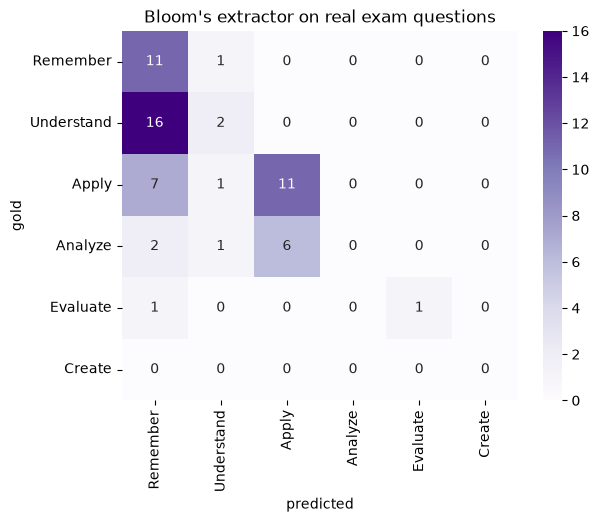

In [9]:
import seaborn as sns
from src.nlp.blooms import BLOOM_LEVELS
cm = np.array(ie['blooms_real_exam_questions']['confusion_matrix'])
sns.heatmap(cm, annot=True, fmt='d', xticklabels=BLOOM_LEVELS, yticklabels=BLOOM_LEVELS, cmap='Purples')
plt.xlabel('predicted'); plt.ylabel('gold'); plt.title("Bloom's extractor on real exam questions"); plt.show()

In [10]:
pd.DataFrame(ie['blooms_real_exam_questions']['errors']).head(12)

,question,bloom_level,pred
0,A person may celebrate an equinox,Understand,Remember
1,"According to the correspondence principle,",Remember,Understand
2,"A 10 kg box slides horizontally without friction at a speed of 1 m/s. At one point, a constant force is applied to t...",Apply,Remember
3,What happens when the kidneys cannot remove wastes from the blood?,Understand,Remember
4,When can lunar and solar eclipses take place?,Understand,Remember
5,The structures found in a living cell can be compared to the parts of a factory that produces cars. Which part of th...,Analyze,Remember
6,"A volcano under the ocean slowly releases lava over time. As the lava is released, it cools and hardens on the ocean...",Apply,Understand
7,"If the lengths of two sides of a right triangle are 5 and 12 units, what is the least possible length, in units, of ...",Apply,Remember
8,Which activity is an example of a chemical change?,Understand,Remember
9,Two cats in different rooms may share information by,Understand,Remember


**Insight:** the rule-based extractor is perfect when the command verb is explicit, but real exam questions
often *imply* the cognitive level ("A 10 kg box slides ... The force is"). This motivates learning
difficulty from data instead of relying on rules alone.

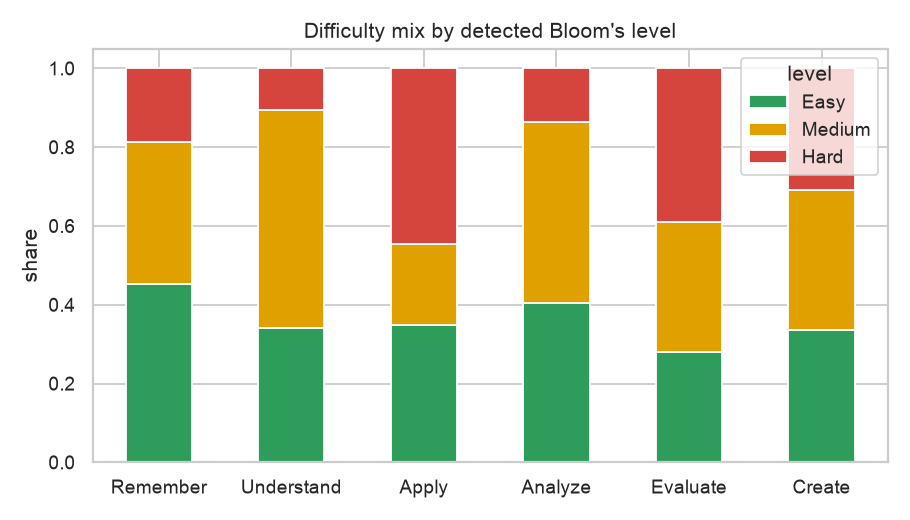

In [11]:
show('bloom_vs_difficulty.png')